In [1]:
import pandas as pd
import numpy as np
import optuna
import lightgbm as lgb
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, matthews_corrcoef,
    precision_recall_curve, roc_curve, confusion_matrix, classification_report
)
import joblib
import os
import warnings

warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)

df = pd.read_parquet('../data/processed/aml_transactions_enriched.parquet')
df = df.sort_values('Timestamp').reset_index(drop=True)

cat_cols = ['Payment_Format', 'Payment_Currency', 'Receiving_Currency']
encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
df[cat_cols] = encoder.fit_transform(df[cat_cols].astype(str)).astype('int16')

feature_cols = [
    # Fitur Dasar & Waktu
    'Amount_Paid', 'Amount_Received', 'Hour', 'DayOfWeek',
    # Fitur Kepatuhan AML
    'Is_Cross_Bank', 'Is_Cross_Currency', 'Is_After_Hours',
    'Is_Structuring_Zone', 'Is_Same_Entity',
    # Fitur Perilaku & Velocity
    'Sender_Hourly_Tx_Count', 'Amount_to_Sender_Avg_Ratio', 'Receiver_Total_In_Tx',
    # Fitur Graf Jaringan Baru (Fan-In, Fan-Out, Pass-Through)
    'Sender_Unique_Receivers', 'Receiver_Unique_Senders',
    'Sender_Total_Out_Tx', 'Sender_Total_Out_Vol',
    'Receiver_Total_In_Vol', 'Amount_to_Receiver_Avg_Ratio',
    'Pair_Tx_Count', 'Time_Since_Last_Sender_Tx',
    'Sender_Prior_In_Vol', 'Pass_Through_Ratio', 'Fan_In_Out_Ratio',
    # Fitur Kategorikal
    'Payment_Format', 'Payment_Currency', 'Receiving_Currency'
]

split_idx = int(len(df) * 0.80)
train_df = df.iloc[:split_idx].copy()
test_df = df.iloc[split_idx:].copy()

X_train, y_train = train_df[feature_cols], train_df['Is_Laundering']
X_test, y_test = test_df[feature_cols], test_df['Is_Laundering']

print(f"Total Fitur: {len(feature_cols)} | Train: {len(X_train):,} | Test: {len(X_test):,}")

Total Fitur: 26 | Train: 4,062,676 | Test: 1,015,669


In [2]:
# 1. Baseline Logistic Regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train.fillna(0))
X_test_scaled = scaler.transform(X_test.fillna(0))

baseline_lr = LogisticRegression(class_weight='balanced', max_iter=300, n_jobs=-1, random_state=42)
baseline_lr.fit(X_train_scaled, y_train)
lr_probs = baseline_lr.predict_proba(X_test_scaled)[:, 1]

# 2. Optuna Tuning LightGBM (Terkalibrasi untuk PR-AUC & ROC-AUC)
pos_train = train_df[train_df['Is_Laundering'] == 1]
neg_train = train_df[train_df['Is_Laundering'] == 0].sample(n=min(400_000, (train_df['Is_Laundering'] == 0).sum()), random_state=42)
tune_df = pd.concat([pos_train, neg_train]).sort_values('Timestamp')

t_split = int(len(tune_df) * 0.80)
X_t_tr, y_t_tr = tune_df.iloc[:t_split][feature_cols], tune_df.iloc[:t_split]['Is_Laundering']
X_t_val, y_t_val = tune_df.iloc[t_split:][feature_cols], tune_df.iloc[t_split:]['Is_Laundering']

def objective(trial):
    params = {
        'objective': 'binary',
        'metric': 'average_precision',
        'boosting_type': 'gbdt',
        'verbosity': -1,
        'random_state': 42,
        'n_jobs': -1,
        'n_estimators': trial.suggest_int('n_estimators', 200, 600),
        'learning_rate': trial.suggest_float('learning_rate', 0.02, 0.12, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 31, 150),
        'max_depth': trial.suggest_int('max_depth', 6, 14),
        'min_child_samples': trial.suggest_int('min_child_samples', 20, 150),
        'subsample': trial.suggest_float('subsample', 0.7, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 5.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 5.0, log=True),
        'scale_pos_weight': trial.suggest_float('scale_pos_weight', 1.0, 15.0)
    }
    model = lgb.LGBMClassifier(**params)
    model.fit(X_t_tr, y_t_tr, eval_set=[(X_t_val, y_t_val)], callbacks=[lgb.early_stopping(35, verbose=False)])
    return average_precision_score(y_t_val, model.predict_proba(X_t_val)[:, 1])

print("Menjalankan Optuna Hyperparameter Tuning (50 Trials)...")
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=50)

print(f"Best Validation PR-AUC: {study.best_value:.4f}")
print("Best Hyperparameters:", study.best_params)

Menjalankan Optuna Hyperparameter Tuning (50 Trials)...
Best Validation PR-AUC: 0.7903
Best Hyperparameters: {'n_estimators': 442, 'learning_rate': 0.022797160703827674, 'num_leaves': 76, 'max_depth': 10, 'min_child_samples': 27, 'subsample': 0.9981390276601162, 'colsample_bytree': 0.9019954200318417, 'reg_alpha': 0.02407233622641527, 'reg_lambda': 0.22887756177980673, 'scale_pos_weight': 7.20918833914286}


=== MATRIKS EVALUASI LENGKAP (OUT-OF-TIME TEST SET: 1.015.669 TRANSAKSI) ===


,Optimal Threshold,Accuracy,Balanced Accuracy,Precision (Fraud),Recall / Sensitivity,F1-Score,PR-AUC (Avg Precision),ROC-AUC,MCC (Matthews Corr)
Model,,,,,,,,,
Logistic Regression (Baseline),0.9425,98.9310%,69.4011%,6.8160%,39.7664%,0.1164,0.0501,0.9687,0.1613
Tuned LightGBM + Graph Features,0.8257,99.9089%,78.7462%,86.5272%,57.5083%,0.6909,0.6627,0.9801,0.7050


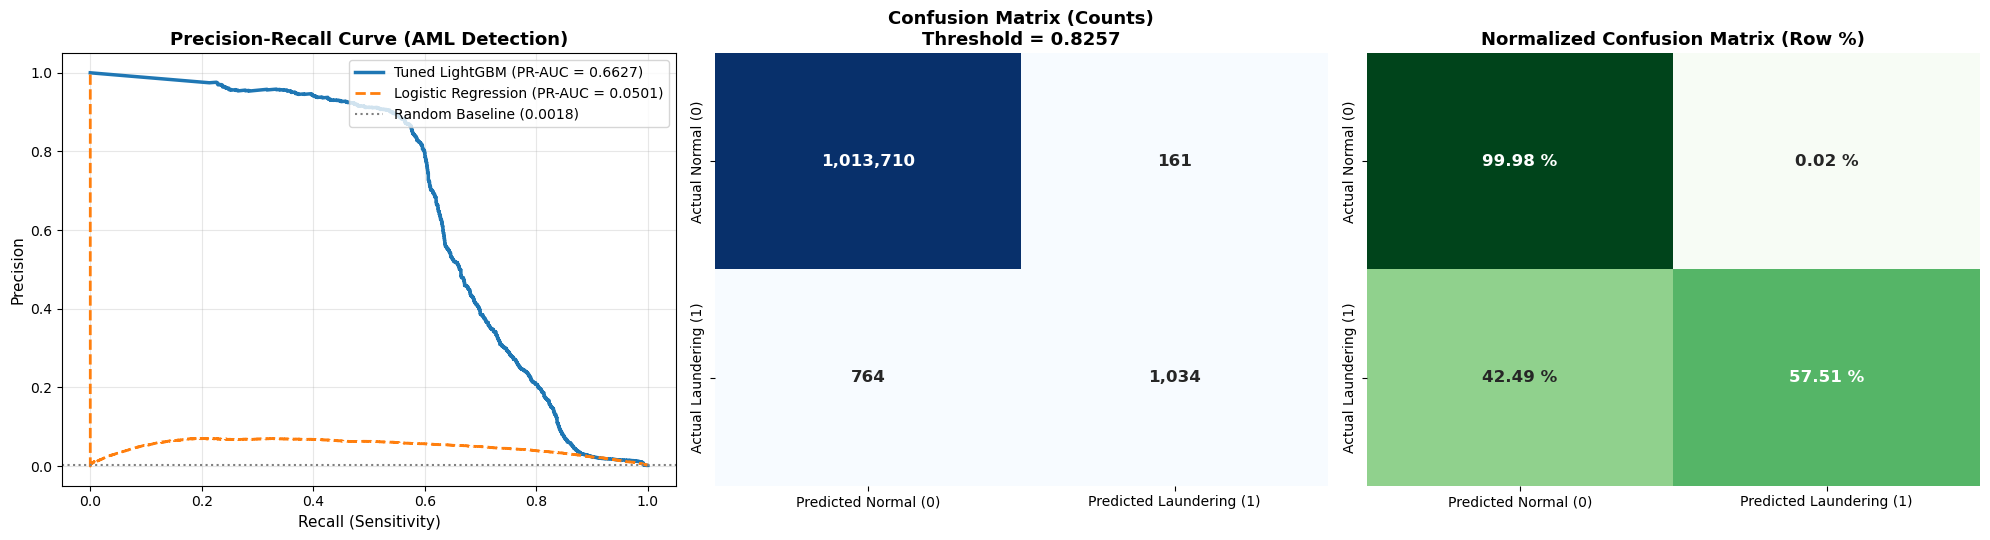

Model dan grafik evaluasi tersimpan di ../models/ dan ../assets/model_evaluation_charts.png


In [3]:
# Train Final LightGBM pada 100% Data Train
best_params = study.best_params.copy()
best_params.update({'objective': 'binary', 'metric': 'average_precision', 'random_state': 42, 'n_jobs': -1, 'verbosity': -1})

final_lgbm = lgb.LGBMClassifier(**best_params)
final_lgbm.fit(X_train, y_train)
lgbm_probs = final_lgbm.predict_proba(X_test)[:, 1]

# Cari Threshold Optimal (Max F1-Score) untuk masing-masing model
def get_metrics(y_true, probs, model_name):
    prec, rec, thresh = precision_recall_curve(y_true, probs)
    f1_arr = 2 * (prec * rec) / (prec + rec + 1e-8)
    best_i = np.argmax(f1_arr)
    opt_th = thresh[best_i] if best_i < len(thresh) else 0.5
    preds = (probs >= opt_th).astype(int)
    
    return {
        'Model': model_name,
        'Optimal Threshold': round(opt_th, 4),
        'Accuracy': f"{accuracy_score(y_true, preds):.4%}",
        'Balanced Accuracy': f"{balanced_accuracy_score(y_true, preds):.4%}",
        'Precision (Fraud)': f"{precision_score(y_true, preds):.4%}",
        'Recall / Sensitivity': f"{recall_score(y_true, preds):.4%}",
        'F1-Score': f"{f1_score(y_true, preds):.4f}",
        'PR-AUC (Avg Precision)': f"{average_precision_score(y_true, probs):.4f}",
        'ROC-AUC': f"{roc_auc_score(y_true, probs):.4f}",
        'MCC (Matthews Corr)': f"{matthews_corrcoef(y_true, preds):.4f}"
    }, preds, opt_th

lr_metrics, lr_preds, lr_th = get_metrics(y_test, lr_probs, "Logistic Regression (Baseline)")
lgbm_metrics, lgbm_preds, lgbm_th = get_metrics(y_test, lgbm_probs, "Tuned LightGBM + Graph Features")

metrics_df = pd.DataFrame([lr_metrics, lgbm_metrics]).set_index('Model')
print("=== MATRIKS EVALUASI LENGKAP (OUT-OF-TIME TEST SET: 1.015.669 TRANSAKSI) ===")
display(metrics_df)

# ================= VISUALISASI: PRECISION-RECALL CURVE & CONFUSION MATRIX =================
os.makedirs('../assets', exist_ok=True)
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))

# Plot 1: Precision-Recall Curve (Perbandingan Baseline vs Tuned LightGBM)
p_lr, r_lr, _ = precision_recall_curve(y_test, lr_probs)
p_lgb, r_lgb, _ = precision_recall_curve(y_test, lgbm_probs)
baseline_rate = y_test.mean()

axes[0].plot(r_lgb, p_lgb, color='#1f77b4', lw=2.5, label=f'Tuned LightGBM (PR-AUC = {average_precision_score(y_test, lgbm_probs):.4f})')
axes[0].plot(r_lr, p_lr, color='#ff7f0e', lw=2, linestyle='--', label=f'Logistic Regression (PR-AUC = {average_precision_score(y_test, lr_probs):.4f})')
axes[0].axhline(baseline_rate, color='gray', linestyle=':', label=f'Random Baseline ({baseline_rate:.4f})')
axes[0].set_title('Precision-Recall Curve (AML Detection)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Recall (Sensitivity)', fontsize=11)
axes[0].set_ylabel('Precision', fontsize=11)
axes[0].legend(loc='upper right')
axes[0].grid(alpha=0.3)

# Plot 2: Confusion Matrix (Counts)
cm = confusion_matrix(y_test, lgbm_preds)
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=axes[1],
            xticklabels=['Predicted Normal (0)', 'Predicted Laundering (1)'],
            yticklabels=['Actual Normal (0)', 'Actual Laundering (1)'],
            annot_kws={'size': 12, 'weight': 'bold'})
axes[1].set_title(f'Confusion Matrix (Counts)\nThreshold = {lgbm_th:.4f}', fontsize=13, fontweight='bold')

# Plot 3: Normalized Confusion Matrix (Recall per Class %)
cm_norm = confusion_matrix(y_test, lgbm_preds, normalize='true') * 100
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Greens', cbar=False, ax=axes[2],
            xticklabels=['Predicted Normal (0)', 'Predicted Laundering (1)'],
            yticklabels=['Actual Normal (0)', 'Actual Laundering (1)'],
            annot_kws={'size': 12, 'weight': 'bold'})
for t in axes[2].texts: t.set_text(t.get_text() + " %")
axes[2].set_title('Normalized Confusion Matrix (Row %)', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig('../assets/model_evaluation_charts.png', dpi=300, bbox_inches='tight')
plt.show()

# Simpan Model Artifact
os.makedirs('../models', exist_ok=True)
joblib.dump({
    'model': final_lgbm,
    'encoder': encoder,
    'features': feature_cols,
    'optimal_threshold': float(lgbm_th),
    'best_params': study.best_params
}, '../models/aml_risk_scorer.pkl')
print("Model dan grafik evaluasi tersimpan di ../models/ dan ../assets/model_evaluation_charts.png")

In [4]:
df['ML_Probability'] = final_lgbm.predict_proba(df[feature_cols])[:, 1]

# Layer 1: Deterministic AML Red-Flag Rules
df['Rule_Penalty'] = (
    df['Is_Structuring_Zone'] * 15 +
    (df['Sender_Hourly_Tx_Count'] >= 5).astype(int) * 15 +
    (df['Receiver_Unique_Senders'] >= 10).astype(int) * 15 +
    df['Is_Cross_Currency'] * 10 +
    df['Is_After_Hours'] * 10 +
    df['Is_Same_Entity'] * 10
)

def get_red_flags(row):
    flags = []
    if row['Is_Structuring_Zone'] == 1: flags.append("Structuring ($8k-$10k)")
    if row['Sender_Hourly_Tx_Count'] >= 5: flags.append("High Velocity (>=5 tx/hr)")
    if row['Receiver_Unique_Senders'] >= 10: flags.append("Fan-In Collector (>=10 senders)")
    if row['Is_Cross_Currency'] == 1: flags.append("Cross-Currency FX")
    if row['Is_After_Hours'] == 1: flags.append("After-Hours Activity")
    if row['Is_Same_Entity'] == 1: flags.append("Same-Entity Layering")
    return ", ".join(flags) if flags else "ML Graph Anomaly"

df['AML_Risk_Score'] = np.clip((df['ML_Probability'] * 80) + df['Rule_Penalty'], 0, 100).round(2)
df['Alert_Tier'] = pd.cut(
    df['AML_Risk_Score'],
    bins=[-1, 39.99, 69.99, 100],
    labels=['Green (Normal)', 'Amber (Watchlist)', 'Red (High-Risk STR)']
)

# Agregasi KRI Tingkat Bank / Unit Kerja
bank_kri = df.groupby('From_Bank').agg(
    Total_Tx=('Amount_Paid', 'count'),
    Total_Volume=('Amount_Paid', 'sum'),
    Red_Alerts=('Alert_Tier', lambda x: (x == 'Red (High-Risk STR)').sum()),
    Amber_Alerts=('Alert_Tier', lambda x: (x == 'Amber (Watchlist)').sum()),
    Structuring_Count=('Is_Structuring_Zone', 'sum'),
    Cross_Currency_Rate=('Is_Cross_Currency', 'mean'),
    After_Hours_Rate=('Is_After_Hours', 'mean'),
    Avg_Risk_Score=('AML_Risk_Score', 'mean')
).reset_index()

bank_kri['Red_Alert_Rate'] = bank_kri['Red_Alerts'] / bank_kri['Total_Tx']
bank_kri['KRI_Status'] = pd.qcut(
    bank_kri['Red_Alert_Rate'].rank(method='first'),
    q=[0, 0.70, 0.90, 1.0],
    labels=['Green (Compliant)', 'Amber (Enhanced Monitoring)', 'Red (Immediate Audit)']
)

decoded_cats = encoder.inverse_transform(df[cat_cols])
df['Payment_Format_Label'] = decoded_cats[:, 0]
df['Payment_Currency_Label'] = decoded_cats[:, 1]

alerts_export = df[df['AML_Risk_Score'] >= 65].copy()
alerts_export['Triggered_Red_Flags'] = alerts_export.apply(get_red_flags, axis=1)

cols_export = [
    'Timestamp', 'From_Bank', 'From_Account', 'From_Entity_Name',
    'To_Bank', 'To_Account', 'To_Entity_Name',
    'Amount_Paid', 'Payment_Currency_Label', 'Payment_Format_Label',
    'Sender_Hourly_Tx_Count', 'Sender_Unique_Receivers', 'Receiver_Unique_Senders',
    'ML_Probability', 'AML_Risk_Score', 'Alert_Tier', 'Triggered_Red_Flags', 'Is_Laundering'
]

alerts_export = alerts_export.sort_values('AML_Risk_Score', ascending=False).head(150_000)[cols_export]

bank_kri.to_parquet('../data/processed/bank_kri_summary.parquet', index=False)
alerts_export.to_parquet('../data/processed/suspicious_alerts.parquet', index=False)
print("Data KRI & Antrean STR siap untuk Streamlit Cloud!")

Data KRI & Antrean STR siap untuk Streamlit Cloud!


In [5]:
# Terapkan prediksi ke seluruh dataset untuk simulasi dashboard monitoring menyeluruh
df['ML_Probability'] = final_lgbm.predict_proba(df[feature_cols])[:, 1]

# 1. Layer 1: Deterministic AML Red-Flag Rules (Penalti Kepatuhan APU-PPT)
df['Rule_Penalty'] = (
    df['Is_Structuring_Zone'] * 15 +
    (df['Sender_Hourly_Tx_Count'] >= 5).astype(int) * 15 +
    df['Is_Cross_Currency'] * 10 +
    df['Is_After_Hours'] * 10 +
    df['Is_Same_Entity'] * 10
)

# Penjelasan Red Flag untuk Analis MRR
def get_red_flags(row):
    flags = []
    if row['Is_Structuring_Zone'] == 1: flags.append("Structuring ($8k-$10k)")
    if row['Sender_Hourly_Tx_Count'] >= 5: flags.append("High Velocity (>=5 tx/hr)")
    if row['Is_Cross_Currency'] == 1: flags.append("Cross-Currency FX")
    if row['Is_After_Hours'] == 1: flags.append("After-Hours Activity")
    if row['Is_Same_Entity'] == 1: flags.append("Same-Entity Layering")
    return ", ".join(flags) if flags else "ML Behavioral Anomaly"

# 2. Hybrid AML Risk Score (0 - 100)
df['AML_Risk_Score'] = np.clip((df['ML_Probability'] * 80) + df['Rule_Penalty'], 0, 100).round(2)

# 3. Pemetaan Alert Triage (Green / Amber / Red)
df['Alert_Tier'] = pd.cut(
    df['AML_Risk_Score'],
    bins=[-1, 39.99, 69.99, 100],
    labels=['Green (Normal)', 'Amber (Watchlist)', 'Red (High-Risk STR)']
)

# 4. Agregasi KRI Tingkat Bank / Unit Kerja (From_Bank) untuk Pemantauan MRR
bank_kri = df.groupby('From_Bank').agg(
    Total_Tx=('Amount_Paid', 'count'),
    Total_Volume=('Amount_Paid', 'sum'),
    Red_Alerts=('Alert_Tier', lambda x: (x == 'Red (High-Risk STR)').sum()),
    Amber_Alerts=('Alert_Tier', lambda x: (x == 'Amber (Watchlist)').sum()),
    Structuring_Count=('Is_Structuring_Zone', 'sum'),
    Cross_Currency_Rate=('Is_Cross_Currency', 'mean'),
    After_Hours_Rate=('Is_After_Hours', 'mean'),
    Avg_Risk_Score=('AML_Risk_Score', 'mean')
).reset_index()

bank_kri['Red_Alert_Rate'] = bank_kri['Red_Alerts'] / bank_kri['Total_Tx']
bank_kri['KRI_Status'] = pd.qcut(
    bank_kri['Red_Alert_Rate'].rank(method='first'),
    q=[0, 0.70, 0.90, 1.0],
    labels=['Green (Compliant)', 'Amber (Enhanced Monitoring)', 'Red (Immediate Audit)']
)

# 5. Ekspor Ringkasan & Top Investigation Alerts (< 25 MB agar siap GitHub & Streamlit Cloud)
# Decode kembali Payment_Format & Currency agar terbaca jelas di dashboard
decoded_cats = encoder.inverse_transform(df[cat_cols])
df['Payment_Format_Label'] = decoded_cats[:, 0]
df['Payment_Currency_Label'] = decoded_cats[:, 1]

alerts_export = df[df['AML_Risk_Score'] >= 65].copy()
alerts_export['Triggered_Red_Flags'] = alerts_export.apply(get_red_flags, axis=1)

cols_export = [
    'Timestamp', 'From_Bank', 'From_Account', 'From_Entity_Name',
    'To_Bank', 'To_Account', 'To_Entity_Name',
    'Amount_Paid', 'Payment_Currency_Label', 'Payment_Format_Label',
    'Sender_Hourly_Tx_Count', 'Amount_to_Sender_Avg_Ratio',
    'ML_Probability', 'AML_Risk_Score', 'Alert_Tier', 'Triggered_Red_Flags', 'Is_Laundering'
]

# Ambil maksimal 150.000 alert tertinggi jika jumlahnya sangat besar agar ukuran file tetap ramping
alerts_export = alerts_export.sort_values('AML_Risk_Score', ascending=False).head(150_000)[cols_export]

bank_kri.to_parquet('../data/processed/bank_kri_summary.parquet', index=False)
alerts_export.to_parquet('../data/processed/suspicious_alerts.parquet', index=False)

print(f"KRI Unit Bank tersimpan: {len(bank_kri):,} institusi/unit")
print(f"Antrean Investigasi STR tersimpan: {len(alerts_export):,} kasus | Ukuran: {os.path.getsize('../data/processed/suspicious_alerts.parquet')/(1024*1024):.2f} MB")

KRI Unit Bank tersimpan: 30,528 institusi/unit
Antrean Investigasi STR tersimpan: 3,479 kasus | Ukuran: 0.21 MB
